# I-94 Traffic Visualizations

# I-94 Traffic Indicators

## Introduction

Interstate 94 is one of the busiest commuter corridors in the Twin Cities. In this project we explore the **Metro Interstate Traffic Volume** dataset to answer one question: **what are the indicators of heavy traffic on I-94?**

We look at two families of possible indicators:
- **Time**: month of the year, day of the week, and hour of the day
- **Weather**: temperature, rain, snow, cloud cover, and weather type

Along the way, the project demonstrates core exploratory data visualization techniques:
- Visualizing time series data with line plots
- Visualizing correlations with scatter plots
- Speeding up exploratory visualization with pandas
- Comparing graphs side by side using grid charts

The data comes from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume). It contains hourly measurements of westbound traffic on I-94, recorded at a station roughly midway between Minneapolis and St. Paul, MN, from October 2012 to September 2018. Because the station only captures westbound traffic, the results should not be generalized to the entire I-94 highway.

### Loading the Data

First, we import the relevant libraries and load the dataset, then confirm it loaded correctly.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
int_94 = pd.read_csv("Data/Metro_Interstate_Traffic_Volume.csv")

int_94.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


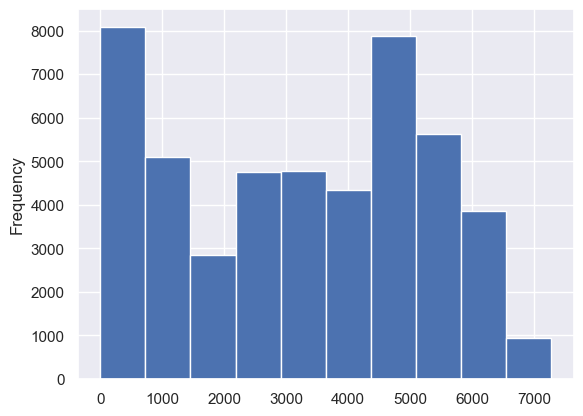

In [3]:
%matplotlib inline
sns.set_theme()

int_94["traffic_volume"].plot.hist(bins=10)
plt.show()

In [4]:
int_94["traffic_volume"].describe()

count    48204.000000
mean      3259.818355
std       1986.860670
min          0.000000
25%       1193.000000
50%       3380.000000
75%       4933.000000
max       7280.000000
Name: traffic_volume, dtype: float64

The descriptive statistics and the histogram show a wide range of traffic volumes. Low volumes are common: 25% of the entries are 1,193 cars or fewer. In contrast, the maximum is 7,280 cars per hour. The histogram is also not a symmetrical bell curve; it is multimodal. This suggests that time of day and other factors influence traffic volume.

## Investigating Time Indicators

Given the shape of the histogram, time of day likely plays a large role in traffic volume. The low-volume mode is probably nighttime driving, when there are far fewer commuters on the road.

To test this, we split the data on the hour in the `date_time` column and separate daytime hours from nighttime hours:
- **Daytime:** 7 a.m. to 7 p.m.
- **Nighttime:** 7 p.m. to 7 a.m.

In [5]:
int_94["date_time"] = pd.to_datetime(int_94["date_time"])

day = int_94.copy()[(int_94['date_time'].dt.hour >= 7) & (int_94['date_time'].dt.hour < 19)]
print(day.shape)

night = int_94.copy()[(int_94['date_time'].dt.hour >= 19) | (int_94['date_time'].dt.hour < 7)]
print(night.shape)

int_94.iloc[176:178]

(23877, 9)
(24327, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
176,NaN,281.17,0.0,0.0,90,Clouds,overcast clouds,2012-10-10 03:00:00,361
177,NaN,281.25,0.0,0.0,92,Clear,sky is clear,2012-10-10 06:00:00,5875


The two datasets are close in size, but `day` has slightly fewer rows than `night`. This is not because any hours are missing. Every hour of the day is recorded, but each daytime hour has a few less records than the nighttime hours, so the daytime total is slightly lower.

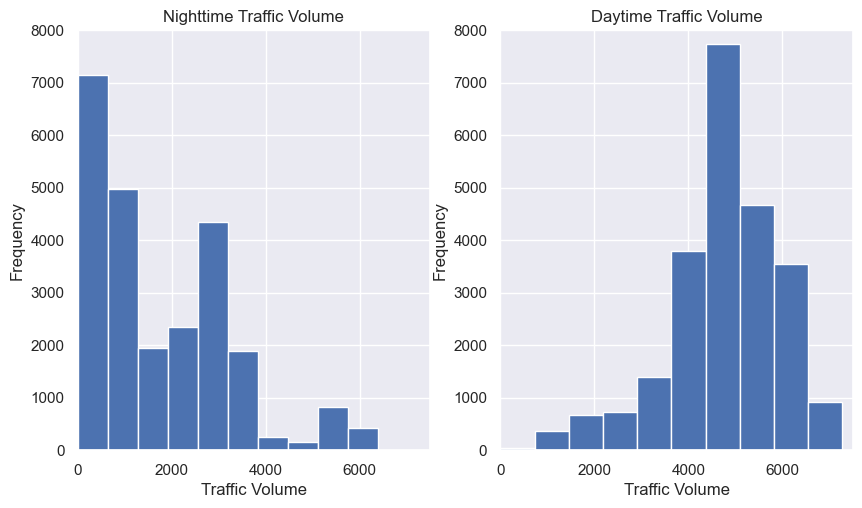

In [6]:
plt.figure(figsize=(10,12))
plt.subplot(2,2,1)
plt.hist(night['traffic_volume'])
plt.title('Nighttime Traffic Volume')
plt.xlabel('Traffic Volume')
plt.ylabel('Frequency')
plt.ylim([0,8000])
plt.xlim([0,7500])

plt.subplot(2,2,2)
plt.hist(day['traffic_volume'])
plt.title('Daytime Traffic Volume')
plt.xlabel('Traffic Volume')
plt.ylabel('Frequency')
plt.ylim([0,8000])
plt.xlim([0,7500])
plt.show()

In [7]:
day['traffic_volume'].describe()

count    23877.000000
mean      4762.047452
std       1174.546482
min          0.000000
25%       4252.000000
50%       4820.000000
75%       5559.000000
max       7280.000000
Name: traffic_volume, dtype: float64

In [8]:
night['traffic_volume'].describe()

count    24327.000000
mean      1785.377441
std       1441.951197
min          0.000000
25%        530.000000
50%       1287.000000
75%       2819.000000
max       6386.000000
Name: traffic_volume, dtype: float64

The histograms and descriptive statistics show two distinct patterns:
- **Nighttime** traffic is right-skewed: most hours are light, with a median of 1,287 cars.
- **Daytime** traffic is left-skewed: most hours are heavy, with a median of 4,820 cars.

This is likely because far fewer people commute at night. There is still some heavier traffic at night, which could come from late commuters, night-shift workers, or long-distance travel.

Because this project focuses on heavy traffic, the rest of the analysis uses only the daytime data.

### Traffic Indicators Over Time

Next, we look at how traffic volume changes with the month, the day of the week, and the time of day.

#### Month

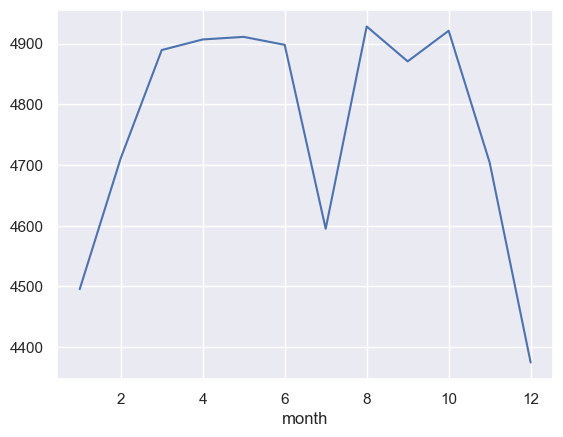

In [9]:
day['month'] = day['date_time'].dt.month
by_month = day.groupby('month').mean(numeric_only=True)
by_month['traffic_volume'].plot.line()
plt.show()

The average monthly traffic volume shows a clear pattern. For most of the year, average traffic is steady at around 4,900 cars per hour. However, volume dips during the winter months (November through February), when Minnesota weather can be especially harsh, with December being the lowest.

There is also an unexpected dip in July (month 7). This could be due to summer vacations and lighter school traffic. To check, let's look at July for each year to see whether the drop is consistent.

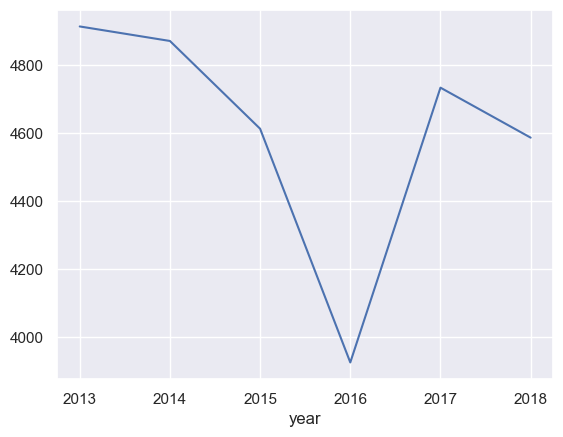

In [10]:
day['year'] = day['date_time'].dt.year
only_july = day[day['month'] == 7]
only_july.groupby('year')['traffic_volume'].mean().plot.line()
plt.show()

In most years, July has an average daytime traffic volume of roughly 4,600 or more. The one notable exception is 2016, when the average dropped below 4,000. This was most likely due to construction on I-94 that year, which closed lanes and diverted traffic.

That single year pulls down the overall July average. Excluding it, July is consistent with the other warm months of the year.

#### Day of the Week

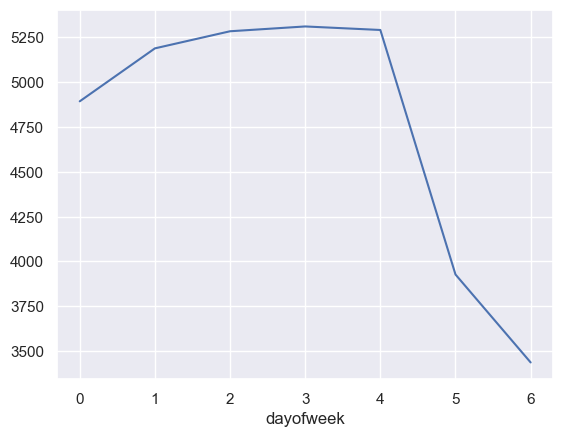

In [11]:
day['dayofweek'] = day['date_time'].dt.dayofweek
by_dayofweek = day.groupby('dayofweek').mean(numeric_only=True)
by_dayofweek['traffic_volume'].plot.line()
plt.show()

The average traffic volume by day of the week shows a clear pattern. The business days, Monday through Friday (0 to 4), all average about 4,900 to 5,300 cars per hour. On the weekend, traffic drops sharply to below 4,000 cars per hour on both Saturday and Sunday.

Because weekend traffic behaves so differently, we analyze business days and weekends separately when looking at time of day.

#### Time of Day

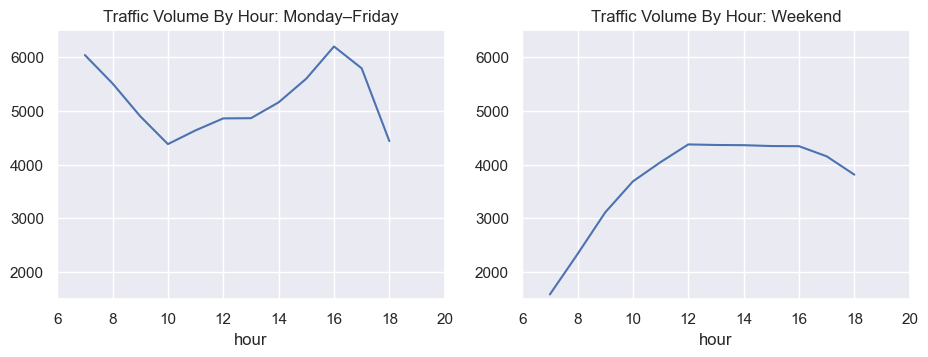

In [12]:
day['hour'] = day['date_time'].dt.hour
business_days = day.copy()[day['dayofweek'] <= 4] # 4 == Friday
weekend = day.copy()[day['dayofweek'] >= 5] # 5 == Saturday
by_hour_business = business_days.groupby('hour').mean(numeric_only=True)
by_hour_weekend = weekend.groupby('hour').mean(numeric_only=True)

plt.figure(figsize=(11,3.5))

plt.subplot(1,2,1)
by_hour_business['traffic_volume'].plot.line()
plt.xlim(6,20)
plt.ylim(1500,6500)
plt.title('Traffic Volume By Hour: Monday–Friday')

plt.subplot(1,2,2) 
by_hour_weekend['traffic_volume'].plot.line()
plt.xlim(6,20)
plt.ylim(1500,6500)
plt.title('Traffic Volume By Hour: Weekend')
plt.show()

The grid chart compares the average traffic volume by hour for business days and weekends. The difference is striking: on business days, almost every hour has more traffic than the corresponding hour on the weekend.

Business day traffic has a distinct bimodal pattern that matches commuting times. The busiest hours are **7 a.m.** (about 6,000 cars) and **4 p.m.** (about 6,200 cars), with a midday slump in between. Weekend traffic instead builds gradually through the morning and levels off in the afternoon.

### Time Indicator Findings

We found three time-based indicators of heavy traffic:
- Traffic is usually heavier during the warmer months (March to October) than the colder months (November to February).
- Traffic is usually heavier on business days than on weekends.
- On business days, the rush hours are 7 a.m. and 4 p.m.

## Investigating Weather Indicators

Timing and seasonality are not the only possible indicators of heavy traffic. Weather is another candidate.

The dataset has six weather columns: `temp`, `rain_1h`, `snow_1h`, `clouds_all`, `weather_main`, and `weather_description`.

### Weather Correlation to Traffic Volume

In [13]:
day.corr(numeric_only=True)['traffic_volume']

temp              0.128317
rain_1h           0.003697
snow_1h           0.001265
clouds_all       -0.032932
traffic_volume    1.000000
month            -0.022337
year             -0.003557
dayofweek        -0.416453
hour              0.172704
Name: traffic_volume, dtype: float64

Of the weather columns, `temp` has the strongest correlation with traffic volume. Even so, the correlation is weak, at only r = 0.13. Rain, snow, and cloud cover have almost no correlation with traffic volume.

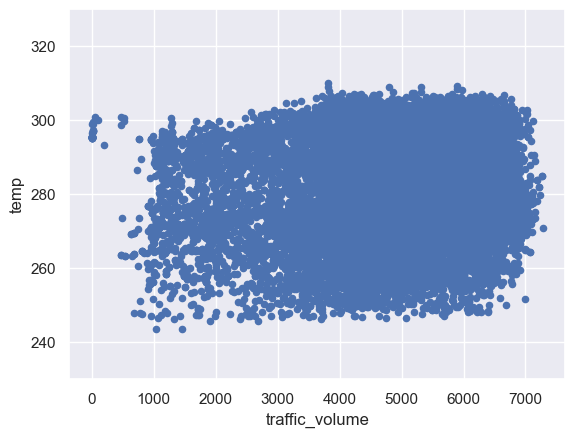

In [14]:
day.plot.scatter('traffic_volume', 'temp')
plt.ylim(230,330)
plt.show()

The scatter plot of temperature (in Kelvin) against traffic volume shows no clear relationship between the two. Since temperature is the most strongly correlated numeric weather column, we can conclude that the numeric weather columns are not reliable indicators of heavy traffic.

### Weather Types as Traffic Indicators

Even though the numeric weather columns are not good indicators of traffic volume, the categorical columns `weather_main` and `weather_description` might be. Let's compare the average traffic volume for each weather type.

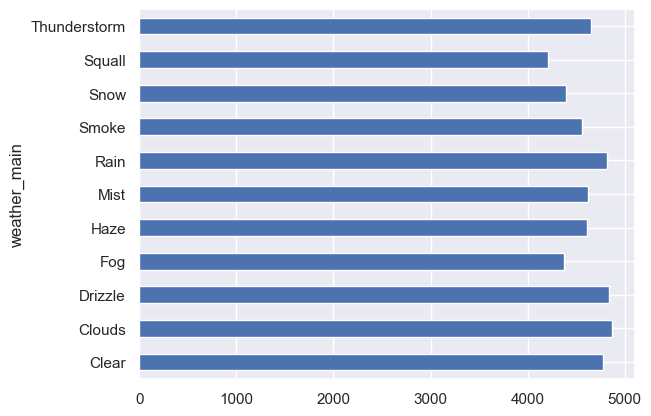

In [15]:
by_weather_main = day.groupby('weather_main').mean(numeric_only=True)
by_weather_description = day.groupby('weather_description').mean(numeric_only=True)

by_weather_main['traffic_volume'].plot.barh()
plt.show()

No general weather condition has an average traffic volume above 5,000 cars per hour. The averages fall between about 4,200 and 4,900, so none of the main weather types are useful indicators of heavy traffic.

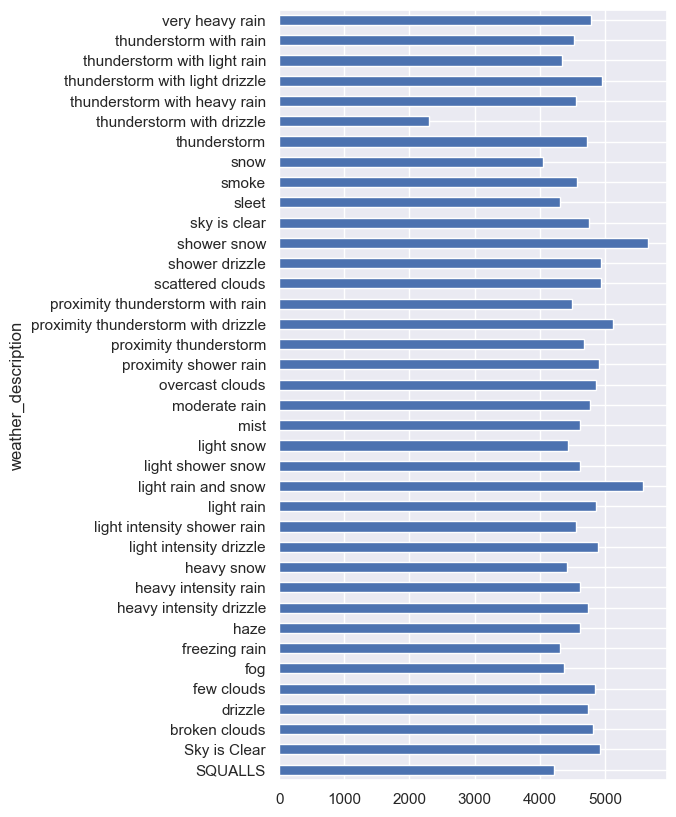

In [16]:
by_weather_description['traffic_volume'].plot.barh(figsize=(5,10))
plt.show()

Three weather descriptions have an average traffic volume above 5,000 cars per hour:
- `shower snow`
- `light rain and snow`
- `proximity thunderstorm with drizzle`

These conditions all involve poor weather and reduced visibility, which could slow traffic and cause congestion. However, they are also very rare in the daytime data: `shower snow` appears only once, `light rain and snow` 4 times, and `proximity thunderstorm with drizzle` 6 times. With so few observations, these averages could easily be due to chance, so they should be treated as possible indicators that need more data to confirm.

## Conclusion

In this project, we explored indicators of heavy westbound traffic on I-94 between Minneapolis and St. Paul. We split the data into daytime and nighttime hours, focused on the heavier daytime traffic, and examined time-based and weather-based indicators.

**Time is the strongest indicator of heavy traffic.** We found three clear time indicators:
- **Season:** Traffic is heavier in the warmer months (March to October) than in the colder months (November to February). The dip in July is mostly explained by I-94 construction in 2016.
- **Day of the week:** Business days average 4,900 to 5,300 cars per hour, compared with under 4,000 on weekends.
- **Time of day:** On business days, traffic peaks during the 7 a.m. and 4 p.m. rush hours, at over 6,000 cars per hour.

**Weather is a weak indicator.** Temperature, rain, snow, and cloud cover have little to no correlation with traffic volume, and no general weather type averages above 5,000 cars per hour. Three specific conditions (`shower snow`, `light rain and snow`, and `proximity thunderstorm with drizzle`) are associated with heavy traffic, but they are based on only 1 to 6 observations each and need more data to confirm.

**In short:** the heaviest traffic on I-94 happens during weekday rush hours in the warmer months. Commuters who can shift their travel outside of 7 a.m. and 4 p.m. on weekdays are likely to see much lighter traffic.